# Лабораторная работа №1: Иерархический кластерный анализ
**Студент:** Любецкая Антонина
**Цель исследования:** Провести иерархическую кластеризацию 48 городов мира на основе экономических показателей (часы работы, индекс цен, индекс зарплат) для выделения однородных экономических зон.
**Гипотеза:** Города разделятся на 3-4 выраженных кластера, соответствующих уровню экономического развития.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

plt.style.use('ggplot')
%matplotlib inline

### Шаг 1: Предобработка и масштабирование данных
В исходных данных присутствуют заглушки -9999 и десятичные запятые вместо системных точек. Заменяем некорректные значения на NaN, переводим колонки в числовой формат и заполняем единичные пропуски медианой. 
Затем применяем StandardScaler. Это необходимо, так как признак Work измеряется тысячами часов, а Price и Salary - десятками единиц. Без масштабирования алгоритм кластеризации будет опираться исключительно на разницу в рабочих часах, игнорируя цены и зарплаты.

In [39]:
# Загрузка данных
df = pd.read_csv("Econom_Cities_data.csv", sep=';', index_col='City')

In [40]:
df.head()

,Work,Price,Salary
City,,,
Amsterdam,1714,"65,6",49
Athens,1792,"53,8","30,4"
Bogota,2152,"37,9","11,5"
Bombay,2052,"30,3","5,3"
Brussels,1708,"73,8","50,5"


In [41]:
print(df)

                Work  Price Salary
City                              
Amsterdam       1714   65,6     49
Athens          1792   53,8   30,4
Bogota          2152   37,9   11,5
Bombay          2052   30,3    5,3
Brussels        1708   73,8   50,5
Buenos_Aires    1971   56,1   12,5
Cairo          -9999   37,1  -9999
Caracas         2041     61   10,9
Chicago         1924   73,9   61,9
Copenhagen      1717   91,3   62,9
Dublin          1759     76   41,4
Dusseldorf      1693   78,5   60,2
Frankfurt       1650   74,5   60,4
Geneva          1880   95,9   90,3
Helsinki        1667  113,6   66,6
Hong_Kong       2375   63,8   27,8
Houston         1978   71,9   46,3
Jakarta        -9999   43,6  -9999
Johannesburg    1945   51,1     24
Kuala_Lumpur    2167   43,5    9,9
Lagos           1786   45,2    2,7
Lisbon          1742   56,2   18,8
London          1737   84,2   46,2
Los_Angeles     2068   79,8   65,2
Luxembourg      1768   71,1   71,1
Madrid          1710   93,8     50
Manila          2268

In [42]:
# Очистка и замена типов данных
df = df.replace([-9999, '-9999'], np.nan)
df['Price'] = pd.to_numeric(df['Price'].astype(str).str.replace(',', '.'), errors='coerce')
df['Salary'] = pd.to_numeric(df['Salary'].astype(str).str.replace(',', '.'), errors='coerce')
df = df.fillna(df.median(numeric_only=True))

In [43]:
# Масштабирование
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns, index=df.index)
df_scaled.head()

,Work,Price,Salary
City,,,
Amsterdam,-0.974577,-0.151250,0.387038
Athens,-0.512818,-0.698647,-0.388428
Bogota,1.618375,-1.436242,-1.176402
Bombay,1.026377,-1.788804,-1.434891
Brussels,-1.010097,0.229145,0.449576


### Шаг 2: Построение дендрограммы и выбор числа кластеров
Для визуального определения оптимального числа кластеров строим дендрограмму с использованием метода Ward (минимизирует дисперсию внутри кластеров) и график «каменистой осыпи».

In [44]:
link = linkage(df_scaled, method='ward', metric='euclidean')

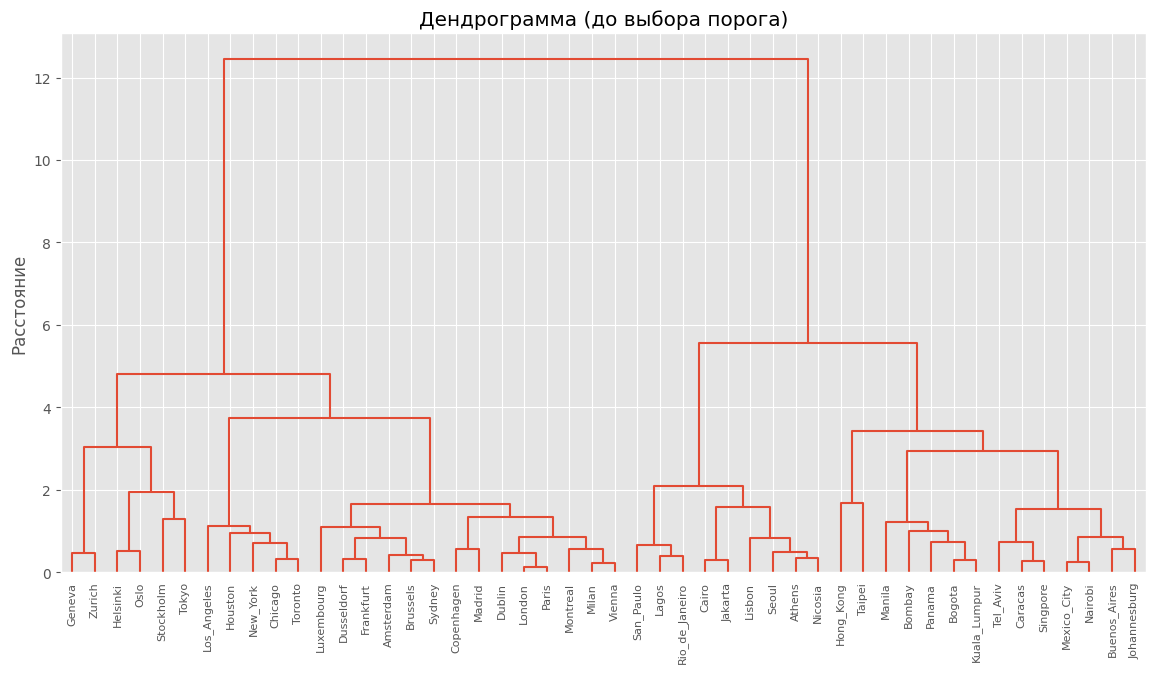

In [45]:
plt.figure(figsize=(14, 7))
dendrogram(link, labels=df_scaled.index.tolist(), leaf_rotation=90, color_threshold=-1)
plt.title('Дендрограмма (до выбора порога)')
plt.ylabel('Расстояние')
plt.show()

In [46]:
# Расстояния объединения (3-й столбец матрицы link)
dist = link[:, 2]

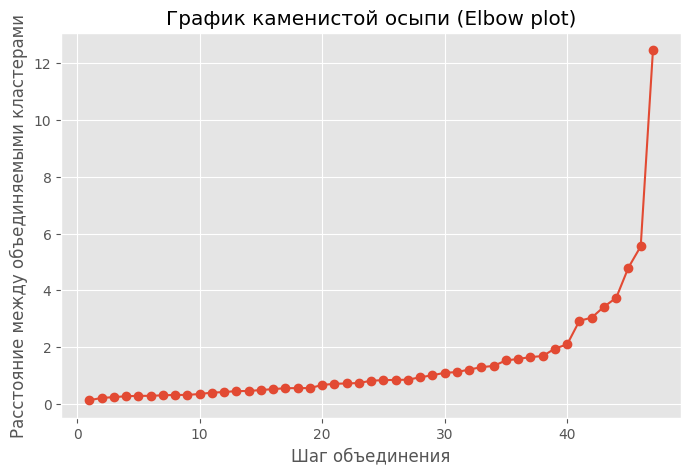

In [47]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(dist) + 1), dist, marker='o')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние между объединяемыми кластерами')
plt.title('График каменистой осыпи (Elbow plot)')
plt.grid(True)
plt.show()

Визуальный анализ дендрограммы и резкий излом на графике каменистой осыпи показывают, что оптимальным является разделение на 3 кластера (пороговая линия на расстоянии около 5.5).

### Шаг 3: Назначение меток кластеров и проверка размеров

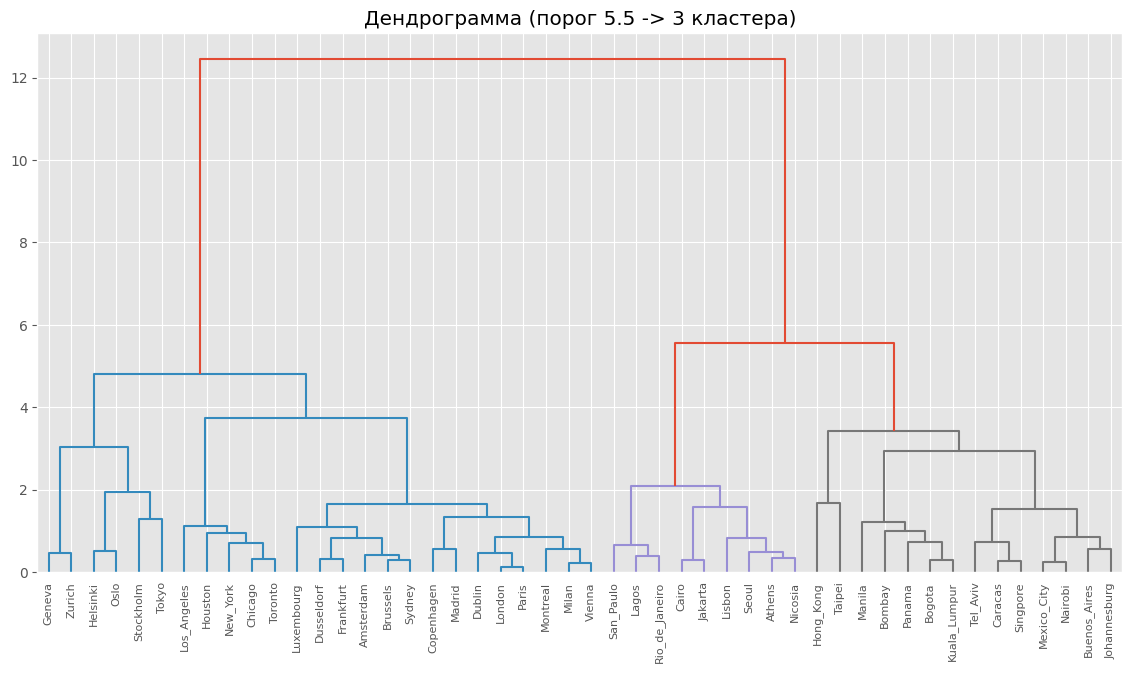

In [48]:
# Цветная дендрограмма с выбранным порогом
plt.figure(figsize=(14, 7))
dendrogram(link, labels=df_scaled.index.tolist(), leaf_rotation=90, color_threshold=5.5)
plt.title('Дендрограмма (порог 5.5 -> 3 кластера)')
plt.show()

In [49]:
# Разбиваем на 3 кластера и добавляем в исходный датафрейм
df['Cluster'] = fcluster(link, t=3, criterion='maxclust')

In [50]:
print("Размеры кластеров:")
print(df['Cluster'].value_counts())

Размеры кластеров:
Cluster
1    25
3    14
2     9
Name: count, dtype: int64


### Шаг 4: Экономическое профилирование кластеров
Для интерпретации полученных групп вычисляем средние значения исходных экономических показателей для каждого кластера.

In [51]:
# Группируем оригинальные данные по кластерам и считаем среднее
cluster_summary = df.groupby('Cluster').mean(numeric_only=True)
round(cluster_summary, 1)

,Work,Price,Salary
Cluster,,,
1,1789.2,85.0,59.0
2,1810.0,48.6,24.6
3,2082.4,53.1,14.9


## Выводы
В ходе иерархического кластерного анализа 48 городов мира были разделены на 3 выраженные экономические зоны:
* **Кластер 1 (Города тяжелого труда):** Характеризуется максимальным количеством рабочих часов при самых низких показателях зарплат.
* **Кластер 2 (Доступные рынки):** Характеризуется самыми низкими ценами на жизнь при средних показателях зарплат и умеренном количестве рабочих часов.
* **Кластер 3 (Высокий уровень жизни):** Характеризуется максимальными зарплатами и высокими ценами, при этом жители работают меньше всего часов.

Выбор 3 кластеров визуально обоснован анализом дендрограммы и подтвержден графиком каменистой осыпи. Выбросов (кластеров из одного наблюдения) не обнаружено. Гипотеза исследования подтверждена.